# 零基础统计学习指南 · 第四章（4.1—4.3.5）

作者：林泓浩。

以手稿前五页与既有学习问答为依据，包含26道小练习及答案、51个编号公式、22个已执行代码块。尚不包含4.4。

在VS Code打开本文件并选择Python内核；工作目录为本文件所在的“第四章”目录。需要numpy、scipy、matplotlib和ipykernel，版本见requirements.txt。按从上到下的顺序运行；Markdown单元解释代码、数学与输出。已保存输出来自全新本地Jupyter内核，未通过VS Code界面自动点击运行。

公式编号与本次PDF一致；点击式号可跳回本Notebook的公式。图保存在“图片”，执行记录在“结果”。本章使用教学数组和给定的舍入系数，没有声称重新拟合Default完整数据。

## 第四章 分类（Classification）

<a id="ref-chap-classification"></a>

> 整理依据：本次依据《统计学习第四章》手稿前五页，接续已学的 4.1—4.3.5。手稿中“GPT”标记按此前讲解展开；练习按既有学习问答整理并附参考答案。手稿第六页的 4.4 留待后续。

**本次学习范围**

从“预测类别究竟在学什么”出发，推导逻辑回归、最大似然、梯度与 Hessian，再学习预测、定性输入、多输入和多类别。红框提示条件与容易混淆之处；公式按章编号，代码、图与后续引用均可回查。

## 4.1　分类概述（An Overview of Classification）

<a id="ref-sec-41"></a>

**本节目标**

区分真实类别、条件概率、拟合概率和最终决策；把第三章的条件均值与本章分类任务接起来。

<a id="ref-topic-c4-target"></a>

### 思考1　预测一个类别，我们究竟在学什么？

银行想根据客户信用卡余额和收入判断是否违约。令输入 $X=(B,I)$，其中 $B$ 是余额，$I$ 是收入；响应 $Y$ 是一个类别。即使两名客户的这些特征相同，最终结果也可能不同，所以我们先学习给定输入后的类别概率。

**手稿编码校正**

手稿开头的标签与后文“违约概率”定义相反。全文统一为 $Y=1$ 表示违约、$Y=0$ 表示不违约。更换标签可以，但概率和系数解释必须随之一起调整。

<a id="ref-eq-c4-target"></a>

$$
p(x)=P(Y=1\mid X=x),\qquad 1-p(x)=P(Y=0\mid X=x).
\tag{4.1}
$$

真实的 $p$ 是数据生成规律的一部分；从有限训练样本估计出的函数记为 $\widehat p$，两者不能混写。实际面对一个新客户时，我们把其输入代入 $\widehat p(x)$，再按业务损失作决策。

<a id="ref-topic-c4-mean"></a>

### 思考2　本章与第三章的条件期望有什么联系？

第三章学习 $E[Y\mid X=x]$。当响应只取 0 和 1 时，按离散随机变量的期望定义：

<a id="ref-eq-c4-bernoulli-mean"></a>

$$
\begin{aligned}E[Y\mid X=x]&=0\cdot P(Y=0\mid X=x)+1\cdot P(Y=1\mid X=x)\\&=p(x).\end{aligned}
\tag{4.2}
$$

因此，二分类中的条件均值恰好等于类别 1 的概率。这是编码为 0/1 后的代数性质；不意味着任何条件均值模型都自动符合概率的取值范围。

<a id="ref-topic-c4-decision"></a>

### 思考3　概率预测与分类决策为什么要分开？

在两种误判代价相同的 0–1 损失下，对已经观察到的 $x$，选择类别1只有在实际为0时出错；选择类别0只有在实际为1时出错。由[式（4.1）](#ref-eq-c4-target)得

<a id="ref-eq-c4-risk"></a>

$$
R(1\mid x)=1-p(x),\qquad R(0\mid x)=p(x).
\tag{4.3}
$$

比较两个条件期望损失：$1-p(x)<p(x)$ 等价于 $p(x)>1/2$。实际用估计概率替代，平局可以约定选1：

<a id="ref-eq-c4-decision"></a>

$$
\widehat g(x)=\mathbf 1\{\widehat p(x)\geq 0.5\}.
\tag{4.4}
$$

**阈值与评价目标**

阈值 0.5 来自等代价的 0–1 损失，并非任何业务的固定规定。极不平衡数据上，总准确率可能掩盖模型对少数类的完全失效；最终应按业务代价和独立评估判断。

### 练习 4.1　概率与一次实际结果

客户真实违约概率为0.3。其条件均值是多少？等代价下预测哪类？最后确实违约，是否说明原决策一定不合理？

**参考答案**

由[式（4.2）](#ref-eq-c4-bernoulli-mean)，条件均值为0.3。预测不违约的期望损失是0.3，预测违约是0.7，故选择不违约。一次违约是有30%概率发生的事件，不能据此否定事前最小风险决策；也不能用单个结果检验整套概率模型是否校准。

### 练习 4.2　高准确率的陷阱

1000名客户中30人违约，模型全部预测不违约。准确率是多少？是否已经是好模型？

**参考答案**

准确率为 $970/1000=97%$，但30名违约者全部漏掉，违约召回率为0。仅靠准确率不能认可它，尤其当漏掉违约的代价很高时。

**本节小结**

先估计类别概率，再根据损失选择动作。真实概率是总体规律；拟合概率来自样本；分类标签是经过决策规则后的输出。接下来检查：把线性回归直接搬过来，会遇到哪些问题？

## 4.2　为什么不使用线性回归？（Why Not Linear Regression?）

<a id="ref-sec-42"></a>

**本节目标**

从概率范围、条件方差和类别编码三个角度，分析线性回归用于分类时的限制。

<a id="ref-topic-c4-range"></a>

### 思考1　既然条件均值就是概率，为什么不直接拟合直线？

可以尝试拟合 $\widehat p(x)=\widehat\beta_0+\widehat\beta_1x$，这称为线性概率模型。问题是直线的输出未被限制在 $[0,1]$。例如：

<a id="ref-eq-c4-bad-line"></a>

$$
\widehat p(x)=-0.1+0.08x,\qquad \widehat p(1)=-0.02,\quad\widehat p(5)=0.3,\quad\widehat p(15)=1.1.
\tag{4.5}
$$

中间点合法，并不能保证所有预测合法。非零斜率的直线若定义在整个实数轴上，必然越出概率范围。在一个有限输入区间内它可能始终合法，因此不能声称“任何线性概率模型都无法使用”。把越界值硬截成0或1，只修补输出范围，没有重新建立合适的概率模型。

<a id="ref-topic-c4-variance"></a>

### 思考2　0/1响应的噪声为什么通常不同方差？

固定 $X=x$，因 $Y^2=Y$，由[式（4.2）](#ref-eq-c4-bernoulli-mean)得

<a id="ref-eq-c4-bernoulli-var"></a>

$$
\begin{aligned}\operatorname{Var}(Y\mid X=x)&=E[Y^2\mid X=x]-\{E[Y\mid X=x]\}^2\\&=p(x)-p(x)^2=p(x)[1-p(x)].\end{aligned}
\tag{4.6}
$$

若写 $\varepsilon=Y-p(X)$，则 $E[\varepsilon\mid X]=0$，但条件方差随 $p(X)$ 变化。概率0.5时方差为0.25，概率0.1时只有0.09。因此第三章同方差误差的经典标准误公式不能直接照搬。

**不要把不同问题混为一谈**

异方差本身不自动导致最小二乘系数有偏；均值设定是否正确、误差条件均值是否为零、标准误公式是否适用，是不同问题。本节指出使用限制，不宣称最小二乘在任何二分类场景都无意义。

<a id="ref-topic-c4-label"></a>

### 思考3　多个类别为什么不能当作有距离的数值来回归？

把商品类别“食品、服装、家具”编码为1、2、3，只是在给类别起代号。平方误差却把预测1、实际3的误差记为4，把预测1、实际2的误差记为1；这种惩罚距离未必有业务含义。交换食品和家具的编号，分类任务没有变化，数值回归的目标与拟合却一般会变化。

这不是 Python 能否接受整数的问题，而是数学目标是否尊重类别含义。类别有自然顺序时可以研究有序模型，但仍不能未经论证就把相邻编号当作等距离。输入变量是定性的，与响应变量是定性的也要区分：第三章给输入做哑变量编码，并没有把类别响应变成连续数量。

### 练习 4.3　越界与条件方差

线性概率预测为 $\widehat p(x)=0.2+0.1x$。$x=9$时预测多少，合法吗？若某位置真实概率为0.8，响应的条件方差是多少？

**参考答案**

预测为1.1，不是合法概率。由[式（4.6）](#ref-eq-c4-bernoulli-var)，真实条件方差为 $0.8(1-0.8)=0.16$。这里真实概率与越界的拟合数值是不同对象。

### 练习 4.4　编号是否改变任务

食品、服装、家具编号为1、2、3，回归预测2.4有什么问题？交换食品与家具的编号，业务任务和线性回归拟合是否都不变？

**参考答案**

2.4本身没有对应的类别含义；四舍五入也额外施加了人为次序和距离。重新编号不改变业务分类任务，但数值平方误差和线性拟合一般会变。问题不在“整数类型不能回归”，而在编码所诱导的几何意义不合理。

**本节小结**

逻辑回归将概率范围直接写进模型，同时使用与0/1响应匹配的 Bernoulli 似然。下一节保留“输入线性组合”的简洁结构，但让它描述对数赔率。

## 逻辑回归（Logistic Regression）

<a id="ref-sec-43"></a>

## 4.3.1　逻辑回归模型（The Logistic Model）

<a id="ref-sec-431"></a>

**标题与表述校正**

手稿把 The Logistic Model 标为4.3.2；按教材应为4.3.1，4.3.2才是参数估计。下文“线性”指对数赔率是输入的线性函数，不是对每个0/1观测取 logit 后做普通最小二乘。

<a id="ref-topic-c4-odds"></a>

### 思考1　从概率到赔率，再到整个实数轴

概率 $p$ 衡量类别1占全部可能结果的比例。赔率（odds）则比较类别1与类别0的概率：

<a id="ref-eq-c4-odds"></a>

$$
O=\frac{p}{1-p},\qquad \operatorname{logit}(p)=\log\frac{p}{1-p},\qquad 0<p<1.
\tag{4.7}
$$

例如 $p=0.2,0.5,0.8$ 对应赔率 $1/4,1,4$；赔率1表示两个结果等可能，赔率4表示类别1的概率是类别0的4倍，并不表示概率等于4。变换经过两步：

<a id="ref-eq-c4-domain"></a>

$$
(0,1)\ \xrightarrow{\ p/(1-p)\ }\ (0,+\infty)\ \xrightarrow{\ \log\ }\ \mathbb R.
\tag{4.8}
$$

严格地说，logit 的输入是概率，不是直接把“0到正无穷”当作概率。其导数与端点极限为

<a id="ref-eq-c4-logit-properties"></a>

$$
\begin{aligned}\frac{d}{dp}\log\frac{p}{1-p}&=\frac1p+\frac1{1-p}=\frac1{p(1-p)}>0,\\\lim_{p\downarrow0}\operatorname{logit}(p)&=-\infty,\qquad\lim_{p\uparrow1}\operatorname{logit}(p)=+\infty.\end{aligned}
\tag{4.9}
$$

它连续、严格递增且覆盖实数轴，所以可以把任意有限的线性预测量映射回唯一合法概率。

<a id="ref-topic-c4-sigmoid"></a>

### 思考2　模型假设是什么？怎样把它解回概率？

设一个输入为 $x$，逻辑回归假设对数赔率为线性函数：

<a id="ref-eq-c4-logit-model"></a>

$$
\log\frac{p(x)}{1-p(x)}=\eta(x)=\beta_0+\beta_1x.
\tag{4.10}
$$

这是模型假设，需要用数据与诊断判断适用性；单凭概率在0和1之间并不能推出它。对[式（4.10）](#ref-eq-c4-logit-model)取指数并移项：

<a id="ref-eq-c4-sigmoid-derive"></a>

$$
\begin{aligned}\frac{p}{1-p}=e^\eta&\iff p=e^\eta(1-p)\\&\iff p+e^\eta p=e^\eta\\&\iff p=\frac{e^\eta}{1+e^\eta}=\frac1{1+e^{-\eta}}.\end{aligned}
\tag{4.11}
$$

代回去检查：$1-p=1/(1+e^\eta)$，故 $p/(1-p)=e^\eta$，取对数确实回到 $\eta$。有限 $\eta$ 对应严格介于0和1之间的概率；达到0或1需要极限。$\beta_0$ 是 $x=0$ 时的对数赔率，若零点远离数据范围，解释截距要谨慎。

<a id="ref-topic-c4-why-logit"></a>

### 思考3　为什么选logit，而不是别的变换？

logit并非唯一选择。例如使用标准正态分布函数 $\Phi$，令 $\Phi^{-1}(p)=\eta$，得到 probit 模型。选logit有三点便利：概率范围自动满足；系数可以解释为对数赔率的增量；它与 Bernoulli 分布的对数概率质量函数自然配合。

第三点可直接算出来。对 $y\in\{0,1\}$，单个观测的概率质量为 $p^y(1-p)^{1-y}$。取对数再使用[式（4.11）](#ref-eq-c4-sigmoid-derive)：

<a id="ref-eq-c4-canonical"></a>

$$
\begin{aligned}\log\{p^y(1-p)^{1-y}\}&=y\log p+(1-y)\log(1-p)\\&=y\log\frac p{1-p}+\log(1-p)\\&=y\eta-\log(1+e^\eta).\end{aligned}
\tag{4.12}
$$

因此 logit 是 Bernoulli 指数族的自然参数。这解释了为什么后面的求导特别简洁，并不意味着自然参数只能是输入的线性函数；线性形式仍是建模选择。此前暂缓的贝叶斯推导不在这里展开。

### 练习 4.5　概率、赔率与符号

若 $p=0.2$，赔率是多少？对数赔率为正还是负？

**参考答案**

赔率为 $0.2/0.8=1/4$，其对数为 $\log(1/4)<0$。负的对数赔率只表示类别1比类别0少见，不是负概率。

### 练习 4.6　从线性预测量求概率

$\eta(x)=-2+0.5x$。求 $x=4$ 与 $x=6$ 时的 $\eta$ 和概率。

**参考答案**

$x=4$时 $\eta=0$，概率为 $1/(1+e^0)=0.5$；$x=6$时 $\eta=1$，概率为 $e/(1+e)\approx0.7311$。不能把线性预测量1直接当作概率。

<a id="ref-topic-c4-coefficients"></a>

### 思考4　系数改变的是赔率，还是概率？

令 $O(x)=p(x)/(1-p(x))$。由[式（4.10）](#ref-eq-c4-logit-model)，输入增加 $\Delta$ 后：

<a id="ref-eq-c4-odds-ratio"></a>

$$
\begin{aligned}\log O(x+\Delta)-\log O(x)&=\beta_1\Delta,\\\frac{O(x+\Delta)}{O(x)}&=e^{\beta_1\Delta}.\end{aligned}
\tag{4.13}
$$

所以 $e^{\beta_1}$ 是输入增加一单位的赔率比（odds ratio, OR）。输入单位必须明确：一元、一千元和一万元对应的系数数值不同。

假设赔率乘以 $R>0$，原概率为 $p$、新概率为 $q$，可以逐步解出

<a id="ref-eq-c4-or-probability"></a>

$$
\frac q{1-q}=R\frac p{1-p}\quad\Longrightarrow\quad q(1-p)=Rp(1-q)\quad\Longrightarrow\quad q=\frac{Rp}{1-p+Rp}.
\tag{4.14}
$$

赔率翻倍时，原概率0.2变为 $1/3$，原概率0.5变为 $2/3$，既不是都翻倍，也不是增加相同的概率。

<a id="ref-topic-c4-derivative"></a>

### 思考5　概率对输入的局部变化率怎样求？

先对 $\eta$ 求导，再乘 $d\eta/dx=\beta_1$。由[式（4.11）](#ref-eq-c4-sigmoid-derive)，

<a id="ref-eq-c4-derivative"></a>

$$
\begin{aligned}\frac{dp}{d\eta}&=\frac{e^\eta(1+e^\eta)-e^{2\eta}}{(1+e^\eta)^2}=\frac{e^\eta}{(1+e^\eta)^2}=p(1-p),\\\frac{dp(x)}{dx}&=\beta_1p(x)[1-p(x)].\end{aligned}
\tag{4.15}
$$

符号与 $\beta_1$ 相同，但大小随位置改变。因为 $p(1-p)=1/4-(p-1/2)^2$，在 $p=1/2$ 处绝对变化率最大，趋近0或1时变小。导数描述局部变化；较大输入增量应把两端概率相减，不应把某一点的导数当作全区间恒定斜率。

<a id="ref-code-431-01"></a>

### 代码 4.3.1-01　观察概率曲线与局部变化率

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/431-01.html)

p(0) = 0.50, derivative at 0 = 0.25


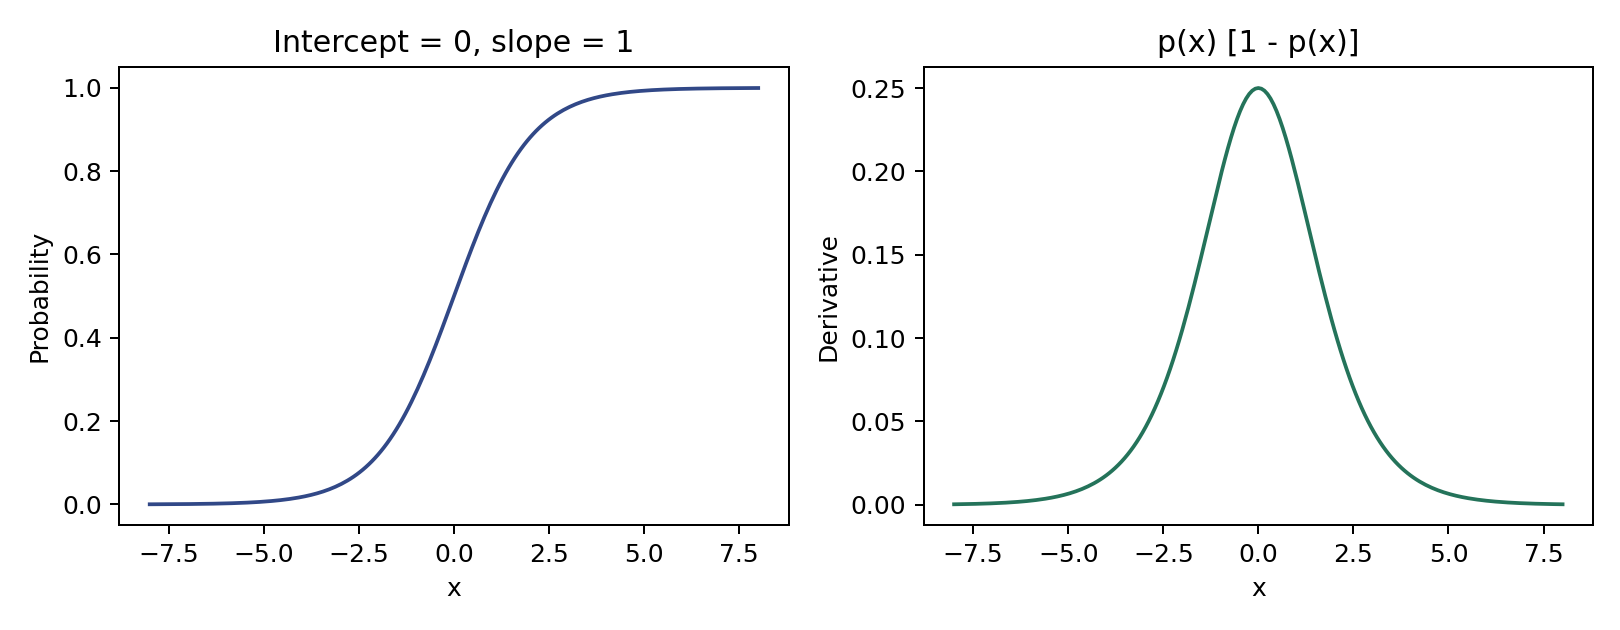

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

image_dir = Path('图片')
image_dir.mkdir(exist_ok=True)
x_curve = np.linspace(-8.0, 8.0, 201)
p_curve = 1.0 / (1.0 + np.exp(-x_curve))
slope_curve = p_curve * (1.0 - p_curve)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(x_curve, p_curve, color='#314887')
axes[0].set(xlabel='x', ylabel='Probability', title='Intercept = 0, slope = 1')
axes[1].plot(x_curve, slope_curve, color='#24735A')
axes[1].set(xlabel='x', ylabel='Derivative', title='p(x) [1 - p(x)]')
fig.tight_layout()
fig.savefig(image_dir / '431-logistic.png', dpi=180)
plt.close(fig)
print(f'p(0) = {0.5:.2f}, derivative at 0 = {0.25:.2f}')


**逐步读代码**

- 本块可直接作为Notebook起点。np是NumPy，plt是绘图模块，Path管理文件路径。image_dir指向当前工作目录下的“图片”；mkdir(exist_ok=True)创建目录，已存在时不因重复创建而报错。

- linspace(-8, 8, 201)包含两端点，均匀生成201个输入；np.exp逐元素计算指数。这里截距0、斜率1，所以导数为p_curve * (1-p_curve)。数组乘法*是逐元素乘法。

- subplots(1, 2)创建一行两张子图；axes[0]和axes[1]分别指向它们。plot绘制曲线；set一次设置横轴、纵轴和标题。十六进制颜色只是外观设置，不必背诵。

- tight_layout调整间距；savefig把图保存到图片目录，dpi控制位图分辨率；close释放图对象。f字符串中的:.2f表示保留两位小数。此图仅呈现已推导公式，不是根据客户数据拟合的结果。

<a id="ref-fig-c4-431-logistic"></a>

图 4.1：观察概率曲线与局部变化率。上方为实际绘图输出；原图保存在 `图片/431-logistic.png`。

### 练习 4.7　单位增量与赔率比

余额单位为千元，系数为 $\log2$。余额增加2000元，赔率变为几倍？概率也变为相同倍数吗？

**参考答案**

增加2000元等于模型输入增加2，故赔率比为 $e^{2\log2}=4$。概率变化按[式（4.14）](#ref-eq-c4-or-probability)计算，通常不是4倍。

### 练习 4.8　同一系数，不同概率斜率

$\beta_1=-0.4$。概率随输入上升还是下降？$p=0.5$与 $p=0.1$处的导数分别是多少？

**参考答案**

均下降。由[式（4.15）](#ref-eq-c4-derivative)，两处导数分别为 $-0.4\times0.5\times0.5=-0.1$ 和 $-0.4\times0.1\times0.9=-0.036$；前者绝对变化率更大。

**本节小结**

线性的是对数赔率，不是概率。logit 的逆函数保证概率合法；系数经指数化得到赔率比。接下来不再猜参数，而是用样本构造似然并求解。

## 4.3.2　估计回归系数（Estimating the Regression Coefficients）

<a id="ref-sec-432"></a>

**本节目标**

沿着手稿顺序完成“似然—损失—梯度—Hessian—数值更新—标准误”的连接。梯度与 Hessian 是精确求导；标准误和 Wald 推断是适当大样本条件下的近似，两者不可混为有限样本精确结论。

<a id="ref-topic-c4-likelihood"></a>

### 思考1　给一组参数打分，为什么使用似然？

设观测为 $(x_i,y_i)$，$y_i\in\{0,1\}$。先考虑一个输入，记 $p_i=p_\beta(x_i)$。固定输入并假设响应条件独立，每个观测的概率质量及全体样本的似然为

<a id="ref-eq-c4-likelihood"></a>

$$
P_\beta(Y_i=y_i\mid x_i)=p_i^{y_i}(1-p_i)^{1-y_i},\qquad L(\beta)=\prod_{i=1}^n p_i^{y_i}(1-p_i)^{1-y_i}.
\tag{4.16}
$$

检查这个统一写法：$y_i=1$时为 $p_i$，$y_i=0$时为 $1-p_i$。数据已经观察到后，$y_i$固定，似然是随候选参数变化的评分；它不是“参数为真的概率”。最大似然倾向于让实际发生的标签在模型下具有更高的联合概率。

取三个样本 $x=(0,1,2)$、$y=(0,1,0)$。候选A取截距 $-\log3$、斜率 $\log3$，预测为 $(1/4,1/2,3/4)$；候选B取两个系数均为0，三个预测均为 $1/2$。

<a id="ref-eq-c4-likelihood-example"></a>

$$
L_A=\frac34\cdot\frac12\cdot\frac14=\frac3{32},\qquad L_B=\frac12\cdot\frac12\cdot\frac12=\frac18>\frac3{32}.
\tag{4.17}
$$

B优于A只是两个候选之间的比较，还不能证明B是所有参数中的最优值。

<a id="ref-topic-c4-loss"></a>

### 思考2　为什么最大似然变成最小化交叉熵？

对正数而言对数严格递增，因此最大化 $L$ 与最大化 $\ell=\log L$ 等价。取负号改为最小化，再除以正数 $n$ 不改变最优位置：

<a id="ref-eq-c4-loss"></a>

$$
\begin{aligned}\ell(\beta)&=\sum_{i=1}^n\{y_i\log p_i+(1-y_i)\log(1-p_i)\},\\J(\beta)&=-\frac1n\ell(\beta)=-\frac1n\sum_{i=1}^n\{y_i\log p_i+(1-y_i)\log(1-p_i)\}.\end{aligned}
\tag{4.18}
$$

$J$称为平均负对数似然，也就是这里的二元交叉熵。多个概率相乘易下溢，改为对数相加也更方便计算。有限最优参数存在时，可以写 $\widehat\beta\in\arg\min J$；存在性稍后单独检查。

### 练习 4.9　比较两个候选模型

两个标签为 $(1,0)$。A给出概率 $(0.8,0.3)$，B给出 $(0.6,0.1)$。哪一个似然更大？

**参考答案**

$L_A=0.8(1-0.3)=0.56$，$L_B=0.6(1-0.1)=0.54$，所以A更大。第二个标签为0，要取不发生类别1的概率，不能直接相乘两个预测概率。

### 练习 4.10　似然与优化目标

似然是否等于“这组参数为真的概率”？最小化平均负对数似然是否与最大化似然有相同最优参数？

**参考答案**

前者不是：这里把参数作为候选值，计算已观察标签的模型概率质量。后者是，在相同参数集合上且最优值存在时，对数严格递增、取负号及除以正数保留相应极值位置；不需要另加贝叶斯先验。

<a id="ref-topic-c4-gradient"></a>

### 思考3　损失的梯度为什么恰好含有预测减真实？

令带截距的输入列向量 $z_i=(1,x_i)^\top$，参数列向量 $\beta=(\beta_0,\beta_1)^\top$，$\eta_i=z_i^\top\beta$。先把单个损失改写。由[式（4.12）](#ref-eq-c4-canonical)：

<a id="ref-eq-c4-softplus"></a>

$$
\begin{aligned}l_i&=-y_i\log p_i-(1-y_i)\log(1-p_i)\\&=-y_i\{\eta_i-\log(1+e^{\eta_i})\}+(1-y_i)\log(1+e^{\eta_i})\\&=\log(1+e^{\eta_i})-y_i\eta_i.\end{aligned}
\tag{4.19}
$$

先对线性预测量求导，再用链式法则对参数求导：

<a id="ref-eq-c4-gradient-scalar"></a>

$$
\begin{aligned}\frac{\partial l_i}{\partial\eta_i}&=\frac{e^{\eta_i}}{1+e^{\eta_i}}-y_i=p_i-y_i,\\\frac{\partial J}{\partial\beta_0}&=\frac1n\sum_{i=1}^n(p_i-y_i),\qquad\frac{\partial J}{\partial\beta_1}=\frac1n\sum_{i=1}^n x_i(p_i-y_i).\end{aligned}
\tag{4.20}
$$

设计矩阵 $X$ 的第 $i$ 行为 $z_i^\top$。推广到 $d$ 个非截距输入，$X\in\mathbb R^{n\times(d+1)}$，$p,y\in\mathbb R^n$，于是

<a id="ref-eq-c4-gradient"></a>

$$
\nabla J(\beta)=\frac1nX^\top(p-y)\in\mathbb R^{d+1}.
\tag{4.21}
$$

这与线性回归的梯度形式相似，但 $p$ 对参数是非线性的 sigmoid。令梯度为零得到非线性方程，不能直接套用最小二乘正规方程的显式解。

<a id="ref-topic-c4-gd"></a>

### 思考4　怎样从梯度设计一个参数更新？

当前参数为 $\beta$，梯度为 $g$，梯度下降取 $\beta_{\rm new}=\beta-\alpha g$。当 $g\ne0$ 且正步长 $\alpha$足够小时，一阶展开说明这个方向下降：

<a id="ref-eq-c4-gd"></a>

$$
J(\beta-\alpha g)=J(\beta)-\alpha g^\top g+o(\alpha),\qquad \alpha\downarrow0.
\tag{4.22}
$$

它不是“任意大步长都下降”的保证。现在用三个样本，从 $(0,0)$ 出发，先创建矩阵，再分别算概率、梯度和一次更新。Notebook按下列顺序执行，前面的导入也需要先运行。

<a id="ref-code-432-01"></a>

### 代码 4.3.2-01　准备三个样本与截距列

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-01.html)

In [2]:
x = np.array([0.0, 1.0, 2.0])
y = np.array([0.0, 1.0, 0.0])
X = np.column_stack([np.ones(len(x)), x])
beta = np.array([0.0, 0.0])
n = len(y)
print(X)
print('shapes:', X.shape, y.shape, beta.shape)


[[1. 0.]
 [1. 1.]
 [1. 2.]]
shapes: (3, 2) (3,) (2,)


**逐步读代码**

- x和y逐行对应三个虚构客户。np.array创建数组；0.0和1.0是浮点数。x、y的形状均为(3,)。

- len(x)给出样本数3；ones生成3个1。column_stack把全1数组和x并排组成(3, 2)矩阵：第一列对应截距，第二列对应斜率。beta按相同列顺序存两个初始参数，不能颠倒顺序。

- n保存样本数；shape查看各轴长度，属于属性，因此后面没有括号。本块只准备数据和初始参数，还没有完成拟合。

<a id="ref-code-432-02"></a>

### 代码 4.3.2-02　计算概率与平均损失梯度

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-02.html)

In [3]:
eta = X @ beta
p = 1.0 / (1.0 + np.exp(-eta))
grad = X.T @ (p - y) / n
print('eta:', eta)
print('p:', p)
print('gradient:', np.round(grad, 6))


eta: [0. 0. 0.]
p: [0.5 0.5 0.5]
gradient: [0.166667 0.166667]


**逐步读代码**

- @是矩阵乘法：(3, 2)与(2,)得到(3,)，每个元素是一个样本的线性预测子。np.exp逐元素计算指数，第二行把分数变成概率。

- p-y逐元素计算预测概率减真实0/1标签。X.T是转置，形状(2, 3)；与(3,)相乘得到(2,)的梯度。除以n是因为目标取平均；最小化负对数似然使用p-y，不能误写为y-p后仍沿负梯度更新。

- np.round(..., 6)只为打印结果保留六位小数，未把grad本身替换成舍入值。

三个初始概率均为0.5，故 $p-y=(0.5,-0.5,0.5)^\top$。截距梯度为 $0.5/3=1/6$；斜率梯度为 $(0\times0.5+1\times(-0.5)+2\times0.5)/3=1/6$。步长0.6会使两个参数都减少0.1。

<a id="ref-code-432-03"></a>

### 代码 4.3.2-03　一次梯度下降及损失核对

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-03.html)

In [4]:
learning_rate = 0.6
beta_gradient = beta - learning_rate * grad
p_gradient = 1.0 / (1.0 + np.exp(-(X @ beta_gradient)))
loss_before = -np.mean(y * np.log(p) + (1-y) * np.log(1-p))
loss_gradient = -np.mean(
    y * np.log(p_gradient) + (1-y) * np.log(1-p_gradient)
)
print('beta after gradient step:', np.round(beta_gradient, 6))
print('probabilities:', np.round(p_gradient, 6))
print(f'loss before = {loss_before:.6f}')
print(f'loss after = {loss_gradient:.6f}')


beta after gradient step: [-0.1 -0.1]
probabilities: [0.475021 0.450166 0.425557]
loss before = 0.693147
loss after = 0.665630


**逐步读代码**

- learning_rate控制步长；beta_gradient是新数组，原beta仍是[0, 0]，后面可从同一起点比较牛顿法。一次更新不等于训练完成。

- 更新参数后必须重新计算线性预测子和概率，不能拿旧概率评价新参数。np.log是自然对数；y=1时保留log(p)，y=0时保留log(1-p)。

- np.mean对三个样本的对数概率取平均，前面的负号转成损失。本例概率远离0和1，可以直接取对数；正式优化应考虑稳定实现、步长与收敛条件。某个样本可能变差，但整体平均损失仍下降。

**数值实现的范围**

本节用小数组展示算法，不把几步更新称为完整生产级求解器。较大数值时可用 `np.logaddexp(0, eta)` 计算 $\log(1+e^\eta)$，避免直接对巨大指数求和；一般工程还需要稳定的 sigmoid、停止准则、步长控制和分离检查。

### 练习 4.11　沿梯度怎样走

当前梯度为 $(0.2,-0.4)^\top$，学习率为正。一次梯度下降会让截距、斜率分别增大还是减小？

**参考答案**

更新为原参数减去学习率乘梯度，所以截距减小、斜率增大。梯度给出局部上升方向，取负号才是下降方向。

### 练习 4.12　损失下降意味着什么

平均损失由0.69下降到0.66，是否已证明到达最优？是否每个样本的损失都一定下降？

**参考答案**

都不是。它只表明这一步使总平均目标改善，其他参数仍可能更好。总和下降允许部分样本的损失上升；应进一步检查梯度、参数变化和收敛情况。

<a id="ref-topic-c4-hessian"></a>

### 思考5　Hessian的矩阵形式怎样得到？

对[式（4.20）](#ref-eq-c4-gradient-scalar)再次求导。令 $z_{ij}$ 为第 $i$ 个样本第 $j$ 个坐标（截距坐标等于1），使用[式（4.15）](#ref-eq-c4-derivative)的链式结构：

<a id="ref-eq-c4-hessian-entry"></a>

$$
\frac{\partial p_i}{\partial\beta_k}=p_i(1-p_i)z_{ik},\qquad \frac{\partial^2J}{\partial\beta_j\partial\beta_k}=\frac1n\sum_i z_{ij}p_i(1-p_i)z_{ik}.
\tag{4.23}
$$

令 $W=\operatorname{diag}(w_1,\ldots,w_n)$，$w_i=p_i(1-p_i)$，就得到

<a id="ref-eq-c4-hessian"></a>

$$
H_J(\beta)=\nabla^2J(\beta)=\frac1nX^\top W X.
\tag{4.24}
$$

对任意方向 $v\in\mathbb R^{d+1}$，二次型可以写成平方和：

<a id="ref-eq-c4-convexity"></a>

$$
v^\top H_Jv=\frac1n(Xv)^\top W(Xv)=\frac1n\sum_iw_i(z_i^\top v)^2\geq0.
\tag{4.25}
$$

因此 $J$ 是凸函数。参数有限时 $0<p_i<1$，所以 $w_i>0$；若 $X$ 列满秩，任何非零 $v$ 都有 $Xv\ne0$，至少一个平方严格大于0，从而 Hessian 正定、目标严格凸。

<a id="ref-code-432-04"></a>

### 代码 4.3.2-04　用逐行加权计算 Hessian

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-04.html)

In [5]:
weights = p * (1.0 - p)
weighted_X = weights[:, None] * X
H = X.T @ weighted_X / n
print('weights:', weights)
print('weighted X:')
print(weighted_X)
print('Hessian:')
print(np.round(H, 6))


weights: [0.25 0.25 0.25]
weighted X:
[[0.25 0.  ]
 [0.25 0.25]
 [0.25 0.5 ]]
Hessian:
[[0.25     0.25    ]
 [0.25     0.416667]]


**逐步读代码**

- 继续使用初始beta对应的p；weights的每个元素是p_i(1-p_i)，形状(3,)。这些权重随参数变化，不是固定常数。

- weights[:, None]取出所有元素并增加一个轴，把(3,)变为(3, 1)。它与(3, 2)的X相乘时广播到两列，每个样本的一整行乘同一个权重。

- weighted_X等于W @ X，但不必显式保存一个n×n的对角矩阵。X.T @ weighted_X / n得到(2, 2)的平均负对数似然Hessian。

<a id="ref-topic-c4-separation"></a>

### 思考6　严格凸为什么仍不能保证有限的最优参数？

严格凸说明“如果存在最小点，则至多一个”，没有保证最小点一定能在有限参数处取到。取两个样本 $x=(-1,1)$，$y=(0,1)$，截距为0、斜率为 $t>0$。此时两个实际标签的概率都为 $1/(1+e^{-t})$，平均损失为

<a id="ref-eq-c4-separation"></a>

$$
J(0,t)=\log(1+e^{-t})>0\quad(t<\infty),\qquad \lim_{t\to+\infty}J(0,t)=0.
\tag{4.26}
$$

两行设计矩阵 $(1,-1)$ 与 $(1,1)$ 线性独立，但损失只在斜率趋于无穷时逼近下确界，有限参数无法达到0。这是完全分离的简单例子。系数不断变大不一定说明“关系越来越可信”，也可能说明无惩罚MLE不存在。列相关造成的不可辨识与分离造成的不存在，是两种问题。

### 练习 4.13　正定与存在性

$X$列满秩且参数有限时，若无惩罚MLE存在，它是否唯一？能否仅凭Hessian正定就保证有限MLE存在？

**参考答案**

存在时唯一，因为目标严格凸；不能保证存在，[式（4.26）](#ref-eq-c4-separation)给出了满秩但完全分离的反例。

### 练习 4.14　权重与重复特征

若所有 $p_i=0.5$，$W$是什么？如果设计矩阵有两列完全相同，Hessian是否可逆？

**参考答案**

$W=0.25I_n$。两列相同可构造在这两列位置为1和$-1$、其余为0的非零向量 $v$，使 $Xv=0$，因此 $H_Jv=0$，Hessian不可逆。

<a id="ref-topic-c4-newton"></a>

### 思考7　Newton更新为什么需要解一个线性方程？

希望新位置梯度接近零。令位移为 $\Delta$，在当前位置把梯度作一阶展开：

<a id="ref-eq-c4-newton"></a>

$$
0\approx\nabla J(\beta+\Delta)\approx g+H_J\Delta\quad\Longrightarrow\quad H_Js=g,\qquad \beta_{\rm new}=\beta-s,\quad s=-\Delta.
\tag{4.27}
$$

这里线性方程只用来求一次局部更新，不是说原优化问题变成了固定的线性回归。每次参数改变，概率、权重、梯度和Hessian都要重算。沿用[代码 4.3.2-02](#ref-code-432-02)的梯度和[代码 4.3.2-04](#ref-code-432-04)的Hessian：

<a id="ref-eq-c4-newton-example"></a>

$$
\begin{pmatrix}1/4&1/4\\1/4&5/12\end{pmatrix}\begin{pmatrix}s_0\\s_1\end{pmatrix}=\begin{pmatrix}1/6\\1/6\end{pmatrix}\quad\Longrightarrow\quad s_1=0,\quad s_0=2/3.
\tag{4.28}
$$

第二行减第一行得 $(5/12-1/4)s_1=0$，所以 $s_1=0$；代回第一行得 $s_0=2/3$。因此一次Newton更新为 $(-2/3,0)$。程序应解方程，而不是先形成矩阵的逆。

<a id="ref-code-432-05"></a>

### 代码 4.3.2-05　解线性方程得到牛顿步

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-05.html)

In [6]:
step = np.linalg.solve(H, grad)
beta_newton = beta - step
print('step:', np.round(step, 6))
print('beta after Newton step:', np.round(beta_newton, 6))
print('equation check:', np.allclose(H @ step, grad))


step: [0.666667 0.      ]
beta after Newton step: [-0.666667  0.      ]
equation check: True


**逐步读代码**

- linalg是线性代数工具集合。solve(H, grad)求满足H @ step = grad的向量；不是逐元素相除。本例H可逆，才能这样求解。

- beta_newton = beta-step等价于减去H逆乘梯度，但代码没有显式求逆。两分量对应截距和斜率；H的非对角元素让参数方向联合调整。

- allclose检查两组浮点数是否在容差内接近，不要求每一位完全相同。打印True只核验该线性方程求解，不证明整个模型已经收敛。

<a id="ref-code-432-06"></a>

### 代码 4.3.2-06　比较两种更新并重算梯度

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-06.html)

In [7]:
candidates = [
    ('initial', beta),
    ('gradient', beta_gradient),
    ('newton', beta_newton),
]
losses = []
for name, current_beta in candidates:
    current_eta = X @ current_beta
    current_p = 1.0 / (1.0 + np.exp(-current_eta))
    current_loss = -np.mean(
        y * np.log(current_p) + (1-y) * np.log(1-current_p)
    )
    losses.append(current_loss)
    print(name, np.round(current_beta, 6), f'loss = {current_loss:.6f}')
p_newton = 1.0 / (1.0 + np.exp(-(X @ beta_newton)))
grad_newton = X.T @ (p_newton - y) / n
print('gradient after Newton:', np.round(grad_newton, 6))


initial [0. 0.] loss = 0.693147
gradient [-0.1 -0.1] loss = 0.665630
newton [-0.666667  0.      ] loss = 0.636592
gradient after Newton: [0.00591 0.00591]


**逐步读代码**

- candidates是列表，每个元素是“名称、参数数组”组成的二元组。for name, current_beta会把每一对内容拆给两个变量。缩进的语句属于循环，每组参数执行一次。

- 每次用当前参数重新计算概率与损失。losses最初为空列表，append把本轮损失追加到末尾，后面画图沿用同样顺序。

- 循环结束后单独计算牛顿更新点的梯度。结果约[0.005910, 0.005910]，还非零，因此一次损失下降不能替代收敛检查。

<a id="ref-code-432-07"></a>

### 代码 4.3.2-07　画出同一起点的一步损失比较

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-07.html)

Saved comparison of one update from the same initial parameters.


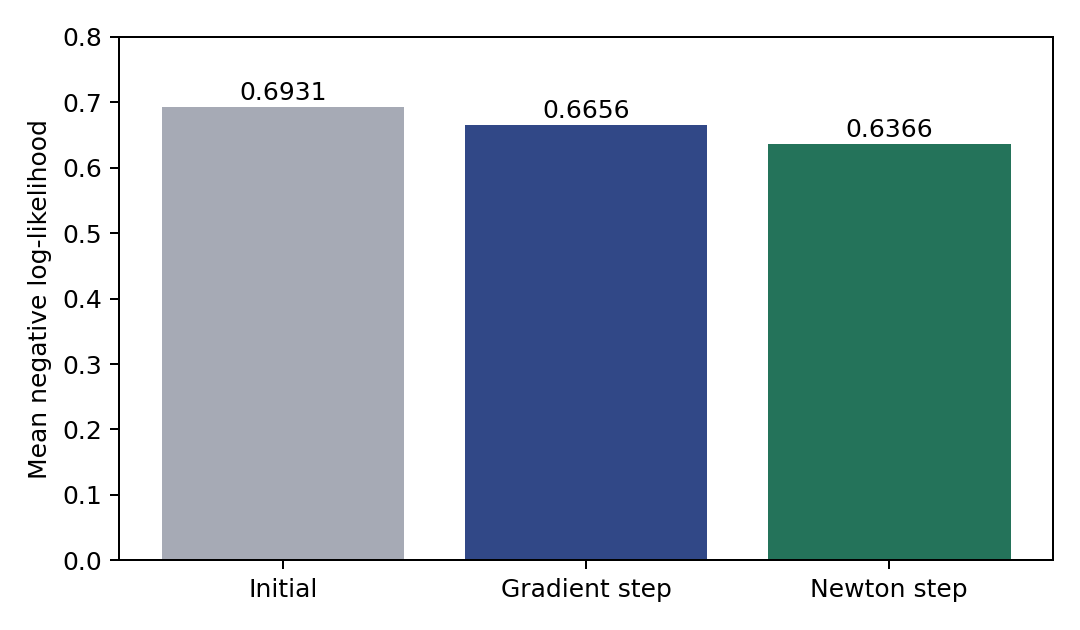

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(['Initial', 'Gradient step', 'Newton step'], losses,
       color=['#A6AAB5', '#314887', '#24735A'])
ax.set(ylabel='Mean negative log-likelihood', ylim=(0, 0.8))
for index, value in enumerate(losses):
    ax.text(index, value + 0.01, f'{value:.4f}', ha='center')
fig.tight_layout()
fig.savefig(image_dir / '432-loss-steps.png', dpi=180)
plt.close(fig)
print('Saved comparison of one update from the same initial parameters.')


**逐步读代码**

- bar绘制柱形图，三根柱分别对应初始、梯度下降一步、牛顿一步的实际损失。不是完整训练曲线，也不能由此宣称牛顿法在所有问题上更快。

- enumerate同时给出从0开始的位置index与该位置的损失value。text在柱顶标数值；ha=center让文字水平居中。ylim固定纵轴范围且从0开始，避免夸大差异。

- 图片来自前面实际计算的losses，保存到同一图片目录。这里的图、Notebook输出与PDF引用的是同一个文件。

<a id="ref-fig-c4-432-loss-steps"></a>

图 4.2：画出同一起点的一步损失比较。上方为实际绘图输出；原图保存在 `图片/432-loss-steps.png`。

Newton这一步损失更低，但新梯度尚不为零，仍不是精确最优解。一般非二次目标的全步Newton也不保证任意初值下都下降，成熟实现常结合阻尼或线搜索；分离与奇异性同样要处理。

### 练习 4.15　逐行加权的维度

100个样本、2个特征并保留截距。写出 $X$、`weights[:, None]`、$WX$和Hessian的形状。

**参考答案**

$X$为 $(100,3)$；一维100个权重增加列轴后为 $(100,1)$；广播乘法对每行3个元素乘同一权重，得到 $(100,3)$；$X^\top WX$为 $(3,3)$。不应把100个样本权重误当成3个系数权重。

### 练习 4.16　解方程与收敛判断

Newton步应解 $H_Js=g$ 还是 $gs=H_J$？一次损失下降后能否马上宣称收敛？

**参考答案**

解 $H_Js=g$，再更新 $\beta-s$。损失下降不等于收敛，需要检查梯度大小、参数或目标变化，并留意系数持续发散；停止容差也应结合数值尺度设置。

<a id="ref-topic-c4-information"></a>

### 思考8　标准误从哪里来？先看总得分的波动

第三章学习过估计量的波动。本节先给逻辑回归的大样本推断主线。固定设计矩阵，假设 Bernoulli 模型正确、响应条件独立，真实参数为有限的 $\beta^\ast$。令总对数似然得分 $U(\beta)=\nabla\ell(\beta)$。由[式（4.18）](#ref-eq-c4-loss)和[式（4.21）](#ref-eq-c4-gradient)，

<a id="ref-eq-c4-score"></a>

$$
U(\beta)=X^\top(y-p_\beta),\qquad E[U(\beta^\ast)\mid X]=0.
\tag{4.29}
$$

在真实参数下，条件独立和[式（4.6）](#ref-eq-c4-bernoulli-var)说明 $\operatorname{Cov}(y\mid X)=W_\ast$。所以

<a id="ref-eq-c4-information"></a>

$$
\begin{aligned}\operatorname{Cov}(U(\beta^\ast)\mid X)&=X^\top W_\ast X=I(\beta^\ast),\\-\nabla^2\ell(\beta)&=X^\top W_\beta X=nH_J(\beta).\end{aligned}
\tag{4.30}
$$

这里 $I$ 是全样本的信息矩阵。它与单样本平均损失的Hessian相差 $n$ 倍，不能丢掉这个因子。

若有限的内部MLE存在、模型可辨识，并满足保证一致性与渐近正态性的适当设计和矩条件，围绕真实参数展开得分：

<a id="ref-eq-c4-score-expansion"></a>

$$
\begin{aligned}0=U(\widehat\beta)&\approx U(\beta^\ast)-I(\beta^\ast)(\widehat\beta-\beta^\ast),\\\widehat\beta-\beta^\ast&\approx I(\beta^\ast)^{-1}U(\beta^\ast).\end{aligned}
\tag{4.31}
$$

把近似线性表示代入协方差，使用[式（4.30）](#ref-eq-c4-information)及信息矩阵的对称性：

<a id="ref-eq-c4-covariance"></a>

$$
\begin{aligned}\operatorname{Cov}(\widehat\beta\mid X)&\approx I^{-1}\operatorname{Cov}(U\mid X)(I^{-1})^\top\\&=I^{-1}I I^{-1}=I^{-1},\\\widehat{\operatorname{Cov}}(\widehat\beta)&=(X^\top\widehat W X)^{-1}=\frac1nH_J(\widehat\beta)^{-1},\\\widehat{\operatorname{SE}}(\widehat\beta_j)&=\sqrt{\big[(X^\top\widehat W X)^{-1}\big]_{jj}}.\end{aligned}
\tag{4.32}
$$

**近似的边界与后续专题**

这里的Taylor展开解释协方差形式；完整证明还需控制余项并证明得分的中心极限定理，属于渐近统计专题。不能把近似协方差当成任意样本量下的精确公式。分离、弱信息、小样本或模型错设时，通常的Wald区间可能不可靠。Bernoulli方差由概率决定，这里没有线性回归中另乘一个估计噪声方差的步骤。

<a id="ref-topic-c4-wald"></a>

### 思考9　怎样检验系数，并给出区间？

检验 $H_0:\beta_j=0$ 对 $H_1:\beta_j\ne0$，使用大样本Wald统计量。令 $\Phi$ 为标准正态分布函数：

<a id="ref-eq-c4-wald"></a>

$$
z_{\rm obs}=\frac{\widehat\beta_j}{\widehat{\operatorname{SE}}(\widehat\beta_j)},\qquad p_{\rm value}=2\{1-\Phi(|z_{\rm obs}|)\}.
\tag{4.33}
$$

双侧5%检验在 $|z_{\rm obs}|>1.96$ 时拒绝零系数；相应近似95%区间与赔率比区间为

<a id="ref-eq-c4-wald-ci"></a>

$$
[L,U]=\widehat\beta_j\pm1.96\widehat{\operatorname{SE}}(\widehat\beta_j),\qquad \operatorname{CI}_{\rm OR}=[e^L,e^U].
\tag{4.34}
$$

指数严格递增，因此只需分别对系数区间两个端点取指数。零系数对应赔率比1，故“系数区间不含0”等价于“赔率比区间不含1”。这是模型参数关联的推断，不自动说明因果关系。

用一个教学计算：系数0.4049、标准误0.115，两者均为给定的舍入数。

<a id="ref-code-432-08"></a>

### 代码 4.3.2-08　计算 Wald z 统计量与双侧 p 值

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-08.html)

In [9]:
from scipy.stats import norm

beta_hat = 0.4049
se = 0.1150
z = beta_hat / se
p_value = 2.0 * norm.sf(abs(z))
print(f'z = {z:.6f}')
print(f'p-value = {p_value:.8f}')


z = 3.520870
p-value = 0.00043013


**逐步读代码**

- norm提供标准正态分布的计算接口。beta_hat和se来自教材表中舍入后的学生系数与标准误，这里不是重新拟合Default数据。

- abs取绝对值；norm.sf(a)计算标准正态右尾概率P(Z>a)。双侧检验用对称性乘2；sf通常比手算1-cdf更适合很小的右尾概率。

- p_value是检验的p值，不是客户违约概率，也不是原假设为真的概率。正态参考分布是正则条件下的大样本近似。

<a id="ref-code-432-09"></a>

### 代码 4.3.2-09　系数区间与赔率比区间

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/432-09.html)

In [10]:
critical = norm.ppf(0.975)
coefficient_ci = np.array([
    beta_hat - critical * se,
    beta_hat + critical * se,
])
odds_ratio_ci = np.exp(coefficient_ci)
print('critical:', round(critical, 6))
print('coefficient CI:', np.round(coefficient_ci, 6))
print('odds ratio CI:', np.round(odds_ratio_ci, 6))


critical: 1.959964
coefficient CI: [0.179504 0.630296]
odds ratio CI: [1.196624 1.878166]


**逐步读代码**

- ppf是分位数函数：norm.ppf(0.975)返回约1.96。双侧95%区间两端各留2.5%，因此上分位点是0.975。

- array按下端点、上端点的顺序保存区间。np.exp对两个端点分别取指数；由于指数严格递增，这就是赔率比的对应区间。

- 系数的无差异值是0，赔率比的无差异值是1。这里是近似Wald区间，不应当作任意小样本下的精确区间。

得到 $z\approx3.521$，双侧 $p\approx0.000430$；系数区间约 $[0.1795,0.6303]$，赔率比区间约 $[1.1966,1.8782]$。程序用生存函数 `sf` 直接求上尾概率，避免用1减去非常接近1的累积概率。第三章在正态线性误差下的精确t检验，与这里的渐近正态z检验不是同一个分布结论。

### 练习 4.17　Wald检验及区间

系数估计为$-0.6$，标准误为0.2。计算z值，判断5%双侧检验，并用1.96构造系数区间。赔率比区间是否包含1？

**参考答案**

$z=-0.6/0.2=-3$，绝对值大于1.96，拒绝零系数。区间为 $[-0.6-0.392,-0.6+0.392]=[-0.992,-0.208]$。整个系数区间在0以下，指数化后的赔率比区间整个在1以下，不包含1。结论依赖前述近似条件。

### 练习 4.18　平均Hessian的样本量因子

一维参数问题，$n=100$，平均负对数似然的Hessian为0.25。估计方差和标准误是多少？

**参考答案**

由[式（4.32）](#ref-eq-c4-covariance)，方差为 $H_J^{-1}/n=4/100=0.04$，标准误为0.2。把 $H_J^{-1}=4$直接当作方差，会漏掉样本量因子。

**本节小结**

数据通过Bernoulli似然定义目标，目标的一阶、二阶导数决定数值更新与信息量。计算最优参数、判断有限解是否存在、评估参数不确定性，是三个相关但不同的工作。接下来固定拟合系数，练习把输入变成预测。

## 4.3.3　进行预测（Making Predictions）

<a id="ref-sec-433"></a>

**本节目标**

按“输入及单位—线性预测量—概率—决策”的顺序计算，并理解定性输入的参考类别。这些例子代入给定系数，不声称本节重新拟合了完整Default数据。

<a id="ref-topic-c4-balance-prediction"></a>

### 思考1　给定余额，怎样得到违约概率？

采用此前讲解的余额单变量模型舍入系数，余额 $B$ 单位为美元：

<a id="ref-eq-c4-balance-model"></a>

$$
\widehat\eta(B)=-10.6513+0.0055B,\qquad \widehat p(B)=\frac1{1+e^{-\widehat\eta(B)}}.
\tag{4.35}
$$

先把新客户余额存入数组，再逐步代入。注意 $-10.6513$ 是截距，不是概率；$0.0055$ 是每美元余额对应的对数赔率增量。

<a id="ref-code-433-01"></a>

### 代码 4.3.3-01　余额预测：系数和输入单位

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/433-01.html)

In [11]:
balance_intercept = -10.6513
balance_slope = 0.0055
balance_new = np.array([1000.0, 2000.0])
print('balances in dollars:', balance_new)


balances in dollars: [1000. 2000.]


**逐步读代码**

- 两个系数是教材余额单变量模型的舍入值；与前面的三样本教学参数无关，使用不同变量名避免误覆盖。

- balance_new存两位新客户的余额，单位为美元而不是千美元。预测阶段只代入已估计系数，不为每一位新客户重新拟合。

<a id="ref-code-433-02"></a>

### 代码 4.3.3-02　从余额计算分数和概率

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/433-02.html)

In [12]:
eta_balance = balance_intercept + balance_slope * balance_new
p_balance = 1.0 / (1.0 + np.exp(-eta_balance))
print('linear scores:', eta_balance)
print('probabilities:', np.round(p_balance, 6))
print('percent:', np.round(100 * p_balance, 4))


linear scores: [-5.1513  0.3487]
probabilities: [0.005759 0.586302]
percent: [ 0.5759 58.6302]


**逐步读代码**

- 标量乘数组会逐元素计算，再给两个结果都加截距。eta_balance和p_balance都是(2,)数组，顺序与输入客户相同。

- 线性分数可以为任意实数，概率则在0和1之间。乘100只是把概率写成百分数，不能把0.005759误读为0.005759%。

<a id="ref-eq-c4-balance-example"></a>

$$
\begin{aligned}\widehat\eta(1000)&=-5.1513,&\widehat p(1000)&\approx0.005759,\\\widehat\eta(2000)&=0.3487,&\widehat p(2000)&\approx0.586302.\end{aligned}
\tag{4.36}
$$

换成百分比约为0.576%和58.630%。这些数值由舍入系数计算，可能与原始未舍入模型略有差异。概率不是断言某个客户必然违约；即使大于0.5，仍有不违约的可能。

<a id="ref-topic-c4-threshold"></a>

### 思考2　阈值如何作用？改变阈值是否要重新拟合？

当规则为 $\widehat p\geq0.5$判违约，利用sigmoid严格递增且在0处为0.5，边界满足 $\widehat\eta=0$：

<a id="ref-eq-c4-balance-boundary"></a>

$$
-10.6513+0.0055B=0\quad\Longrightarrow\quad B=\frac{10.6513}{0.0055}=1936.6.
\tag{4.37}
$$

<a id="ref-code-433-03"></a>

### 代码 4.3.3-03　指定阈值并得到类别

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/433-03.html)

In [13]:
threshold = 0.5
y_pred = (p_balance >= threshold).astype(int)
boundary = -balance_intercept / balance_slope
print('comparison:', p_balance >= threshold)
print('predicted classes:', y_pred)
print(f'balance boundary = {boundary:.1f}')


comparison: [False  True]
predicted classes: [0 1]
balance boundary = 1936.6


**逐步读代码**

- p_balance >= threshold逐元素比较，先得到布尔数组。astype(int)把False变成0、True变成1；约定等于阈值时归为1。

- boundary公式仅对应当前一维正斜率模型、阈值0.5。预测类别变化不意味着概率突然跳变。改变阈值一般只改变决策规则，不必重新估计这些系数。

1936.6只是这个特定模型和阈值对应的余额边界，不是所有客户的自然分界，更不是因果阈值。改变决策阈值可以在同一组预测概率上完成，不必为此重新估计参数；阈值应在适当的验证流程中选择，而不是反复试测试集。

### 练习 4.19　线性预测量与阈值

某客户 $\widehat\eta=0$，概率是多少？阈值改为0.6时预测哪类？$\widehat\eta$本身是概率吗？

**参考答案**

概率为0.5；由于0.5小于0.6，预测类别0。线性预测量是对数赔率，可取任意实数，不是概率。

### 练习 4.20　改变规则是否改变模型

某客户拟合概率0.35。阈值从0.5降为0.3，标签如何变化？概率是否随之变化，是否必须重新拟合？

**参考答案**

标签从0变成1。固定模型下概率仍为0.35，改变的是把概率映射为决策的规则，不必重新拟合；规则的业务效果仍需评估。

<a id="ref-topic-c4-dummy"></a>

### 思考3　输入是学生身份这样的类别，怎样使用？

定义 $S=0$ 为非学生（参考类别），$S=1$ 为学生。以学生身份作为唯一输入，采用给定模型

<a id="ref-eq-c4-student-model"></a>

$$
\widehat\eta(S)=-3.5041+0.4049S.
\tag{4.38}
$$

代入0或1即可，不要对“学生”这个字符串直接做乘法。二元输入使用一个0/1指示变量；若有多个无序输入类别并保留截距，通常用 $K-1$ 个指示变量、留一个参考类别来避免完整哑变量列与截距重复。这里讨论的是输入类别，后面4.3.5才是响应有多个类别。

<a id="ref-code-433-04"></a>

### 代码 4.3.3-04　学生身份：参考组编码

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/433-04.html)

In [14]:
student = np.array([0, 1])
student_intercept = -3.5041
student_slope = 0.4049
print('student indicators:', student)


student indicators: [0 1]


**逐步读代码**

- 0表示非学生，1表示学生，非学生是参考组。这两个元素是查询模型的两种输入状态，不表示训练数据只有两个客户。

- 这是另一个单独拟合的模型。不能把student_slope直接拼到余额单变量模型上，当作已经拟合好的多元模型。

<a id="ref-code-433-05"></a>

### 代码 4.3.3-05　两组的预测概率

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/433-05.html)

In [15]:
eta_student = student_intercept + student_slope * student
p_student = 1.0 / (1.0 + np.exp(-eta_student))
print('linear scores:', eta_student)
print('probabilities:', np.round(p_student, 6))


linear scores: [-3.5041 -3.0992]
probabilities: [0.029196 0.04314 ]


**逐步读代码**

- student为0时只剩截距；为1时在截距上加学生系数。得到的两项依次是非学生、学生的预测概率。

- 这只是组间的未调整比较，没有保持余额和收入相同；即使阈值0.5下两组都预测为0，模型的概率也不相同。

非学生与学生的概率分别约2.920%和4.314%。系数0.4049为正，表示这个未控制余额和收入的单变量模型中，学生的违约赔率更高。

<a id="ref-code-433-06"></a>

### 代码 4.3.3-06　分清赔率比、概率比和概率差

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/433-06.html)

In [16]:
student_or = np.exp(student_slope)
probability_difference = p_student[1] - p_student[0]
probability_ratio = p_student[1] / p_student[0]
print(f'odds ratio = {student_or:.6f}')
print(f'probability difference = {probability_difference:.6f}')
print(f'percentage-point difference = {100*probability_difference:.6f}')
print(f'probability ratio = {probability_ratio:.6f}')


odds ratio = 1.499153
probability difference = 0.013944
percentage-point difference = 1.394447
probability ratio = 1.477619


**逐步读代码**

- np.exp(student_slope)计算学生相对非学生的赔率比。p_student[1]取学生概率，[0]取非学生概率。

- 相减得到概率差，相除得到概率比；概率差乘100后数值单位是百分点。三个指标回答不同问题，不应互换名称。

<a id="ref-eq-c4-student-interpretation"></a>

$$
\frac{\widehat O(S=1)}{\widehat O(S=0)}=e^{0.4049}\approx1.4992,\qquad \widehat p(1)-\widehat p(0)\approx0.01394.
\tag{4.39}
$$

赔率约为1.499倍，概率约为1.478倍，概率差约1.394个百分点。这三个量不同，特别要区分“百分点”和“百分比增幅”。两种客户在阈值0.5下都被分为不违约，也不表示他们的拟合风险相同。

### 练习 4.21　由赔率比还原概率

参考组违约概率为0.1，另一组赔率是它的2倍。另一组概率是多少？是否等于0.2？

**参考答案**

参考赔率为 $0.1/0.9=1/9$，另一组赔率为 $2/9$。因此概率为 $(2/9)/(1+2/9)=2/11\approx0.1818$，不等于0.2。也可直接使用[式（4.14）](#ref-eq-c4-or-probability)。

### 练习 4.22　同标签与因果判断

某模型给学生和非学生的概率分别为0.04和0.03。若都判不违约，能否认为风险相同？单独拟合学生身份是否控制了余额？能否据此认定学生身份造成违约？

**参考答案**

三者都不能。相同分类标签不等于相同概率；只使用身份没有控制余额；观察数据中的统计关联不能自动解释为因果效应。

**本节小结**

每次预测先核对模型、单位和编码。把线性预测量转为概率之后，才应用阈值；赔率比、概率比、概率差分别回答不同问题。

## 4.3.4　多元逻辑回归（Multiple Logistic Regression）

<a id="ref-sec-434"></a>

**本节目标**

同时使用多个输入，区分边际关联与控制其他变量后的条件关联，并建立正确的新样本矩阵。

<a id="ref-topic-c4-multiple"></a>

### 思考1　多个输入怎样共同进入模型？

用余额 $B$、以千美元计的收入 $I$ 和学生指示变量 $S$：

<a id="ref-eq-c4-multiple-model"></a>

$$
\log\frac{p(B,I,S)}{1-p(B,I,S)}=\beta_0+\beta_BB+\beta_II+\beta_SS.
\tag{4.40}
$$

所有参数应使用同一个多元模型联合估计，不能把三个单变量模型的系数拼在一起。[式（4.21）](#ref-eq-c4-gradient)与[式（4.24）](#ref-eq-c4-hessian)已经允许设计矩阵有多列，因此估计框架不需要重写。

<a id="ref-topic-c4-conditional"></a>

### 思考2　“固定其他变量”具体是什么意思？

比较两个客户，只让余额增加 $\Delta B$，收入和身份完全相同，两式相减消去其余项：

<a id="ref-eq-c4-conditional-or"></a>

$$
\log O(B+\Delta B,I,S)-\log O(B,I,S)=\beta_B\Delta B,\qquad \frac{O(B+\Delta B,I,S)}{O(B,I,S)}=e^{\beta_B\Delta B}.
\tag{4.41}
$$

这是条件关联。若两个客户的余额和收入都变了，不能只用余额系数解释整个预测差异；如果模型存在交互项，斜率解释还需相应调整。本节讨论当前的加性logit模型。

<a id="ref-topic-c4-reversal"></a>

### 思考3　为什么学生系数可以从正变负？

单变量模型比较两类学生身份的总体风险，多元模型比较余额、收入相同的客户。两个问题不同，系数符号改变不必意味着计算错误。下面是用于说明混合构成的虚构数据，不是Default数据的统计汇总：

|余额组|学生：违约人数/总人数|非学生：违约人数/总人数|
|---|---|---|
|低余额|$1/100=1%$|$18/900=2%$|
|高余额|$180/900=20%$|$30/100=30%$|

每个余额组中学生风险都较低，但学生更多集中在高余额组。按两组实际占比加权：

<a id="ref-eq-c4-mixing"></a>

$$
\begin{aligned}P(Y=1\mid S=1)&=0.1\times0.01+0.9\times0.20=0.181,\\P(Y=1\mid S=0)&=0.9\times0.02+0.1\times0.30=0.048.\end{aligned}
\tag{4.42}
$$

总体学生风险18.1%，高于非学生4.8%，与各余额组内的比较方向相反。全概率公式说明，这来自不同的组别权重。这个例子解释边际与条件关联的差异，不能用来宣称已识别身份或余额的因果作用。

<a id="ref-topic-c4-multiple-predict"></a>

### 思考4　如何在代码里为新客户准备输入？

采用之前学习的多元模型舍入系数：

<a id="ref-eq-c4-multiple-numeric"></a>

$$
\widehat\eta=-10.869+0.00574B+0.003I-0.6468S,\qquad I=\text{收入（美元）}/1000.
\tag{4.43}
$$

这里学生系数为负，与单变量模型[式（4.38）](#ref-eq-c4-student-model)的正系数并不矛盾。取两个客户余额均1500美元、收入均40000美元，身份分别为学生和非学生：

<a id="ref-code-434-01"></a>

### 代码 4.3.4-01　多元预测的输入顺序与单位

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/434-01.html)

In [17]:
beta_multi = np.array([-10.8690, 0.00574, 0.0030, -0.6468])
new_customers = np.array([
    [1500.0, 40.0, 1.0],
    [1500.0, 40.0, 0.0],
])
print('new input shape:', new_customers.shape)


new input shape: (2, 3)


**逐步读代码**

- beta_multi依次对应截距、余额、收入、学生指示变量。余额系数使用教材预测公式中的0.00574，比系数表0.0057多保留一位。

- 每行是一个客户，三列顺序固定。余额单位美元；收入单位千美元，年收入40000美元输入40。两行只在学生身份上不同。

<a id="ref-code-434-02"></a>

### 代码 4.3.4-02　加入截距列并做矩阵乘法

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/434-02.html)

In [18]:
X_new = np.column_stack([
    np.ones(len(new_customers)),
    new_customers,
])
eta_multi = X_new @ beta_multi
print(X_new)
print('shapes:', X_new.shape, beta_multi.shape, eta_multi.shape)


[[1.0e+00 1.5e+03 4.0e+01 1.0e+00]
 [1.0e+00 1.5e+03 4.0e+01 0.0e+00]]
shapes: (2, 4) (4,) (2,)


**逐步读代码**

- len(new_customers)返回行数2。column_stack将两个1添加为第一列，得到(2, 4)矩阵，不要再次在其他位置重复添加截距。

- @把每行四个输入与四个系数对应相乘再求和，得到形状(2,)的线性分数。系数顺序错误时，形状仍可能合法但业务计算已经错误。

<a id="ref-code-434-03"></a>

### 代码 4.3.4-03　控制相同输入后的概率与赔率比

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/434-03.html)

In [19]:
p_multi = 1.0 / (1.0 + np.exp(-eta_multi))
print('linear scores:', eta_multi)
print('probabilities:', np.round(p_multi, 6))
print(f'conditional student odds ratio = {np.exp(beta_multi[3]):.6f}')


linear scores: [-2.7858 -2.139 ]
probabilities: [0.058096 0.105364]
conditional student odds ratio = 0.523719


**逐步读代码**

- 先将两个分数转换为概率；第一行学生、第二行非学生，不能凭概率高低猜行的身份。

- beta_multi[3]是第4个系数，即学生系数。它的指数是保持余额和收入不变的赔率比，不能解释为因果效果。

<a id="ref-eq-c4-multiple-predictions"></a>

$$
\begin{aligned}\widehat\eta(1500,40,1)&=-10.869+8.61+0.12-0.6468=-2.7858,\\\widehat\eta(1500,40,0)&=-2.139,\\\widehat p(1500,40,1)&\approx0.05810,\qquad\widehat p(1500,40,0)\approx0.10536.\end{aligned}
\tag{4.44}
$$

固定余额收入，学生赔率是非学生的 $e^{-0.6468}\approx0.5237$ 倍。两行输入乘四个参数时，需要在特征前补一列1来对应截距；列的顺序必须与系数顺序一致。

### 练习 4.23　单位与条件赔率比

收入60000美元在本模型中应填多少？余额增加100美元、其他变量固定，赔率乘几倍？概率也乘这个数吗？

**参考答案**

收入应填60。余额对应的对数赔率增量为 $0.00574\times100=0.574$，赔率比为 $e^{0.574}\approx1.7754$。概率不是直接乘这个数，应通过[式（4.14）](#ref-eq-c4-or-probability)换算。

### 练习 4.24　系数翻转是否矛盾

总体学生违约率较高，但控制余额和收入后学生系数为负，矛盾吗？该系数比较哪些客户？能否解释为身份的因果效应？

**参考答案**

不矛盾；总体比较包含两组不同的余额收入构成，控制后的系数比较余额收入相同、身份不同的客户。统计控制并不自动消除所有混杂，也不自动建立因果效应。

**本节小结**

多元模型在同一个logit中联合使用输入。解释一个系数时，说明固定了什么、增加了多少单位，以及比较的是赔率。下一节把“一个二元响应”推广为“一个多类别响应”。

## 4.3.5　多项逻辑回归（Multinomial Logistic Regression）

<a id="ref-sec-435"></a>

**手稿概念校正**

这里不是“有多个响应变量”，而是一个响应变量有多个互斥类别。输入可有一个或多个。“多元”强调多个输入；“多项”在本节强调响应具有多个类别。

<a id="ref-topic-c4-multiclass"></a>

### 思考1　一个工单有三个可能类别，应该输出什么？

把客服工单分为A物流咨询、B退款处理、C商品咨询，每个工单只属于一类。模型要给出完整概率向量：

<a id="ref-eq-c4-simplex"></a>

$$
p_A(x)+p_B(x)+p_C(x)=1,\qquad p_k(x)\geq0.
\tag{4.45}
$$

若三个独立二分类模型分别给出0.7、0.6、0.4，直接拼接会得到总和1.7，不是互斥类别的联合概率向量。多项逻辑回归通过同一个归一化分母保证约束。

<a id="ref-topic-c4-softmax"></a>

### 思考2　以一个类别为参考，怎样推出归一化概率？

令A为参考类，规定其得分 $\eta_A=0$；为另外两类分别建立相对于A的对数概率比：

<a id="ref-eq-c4-multinomial-logit"></a>

$$
\log\frac{p_B(x)}{p_A(x)}=\eta_B(x)=z^\top\beta_B,\qquad \log\frac{p_C(x)}{p_A(x)}=\eta_C(x)=z^\top\beta_C.
\tag{4.46}
$$

注意分母是参考类概率 $p_A$，不是 $1-p_B$ 或 $1-p_C$。先取指数，得到 $p_B=e^{\eta_B}p_A$、$p_C=e^{\eta_C}p_A$；再代入[式（4.45）](#ref-eq-c4-simplex)：

<a id="ref-eq-c4-softmax-derive"></a>

$$
\begin{aligned}p_A+e^{\eta_B}p_A+e^{\eta_C}p_A&=1,\\p_A&=\frac1{1+e^{\eta_B}+e^{\eta_C}},\\p_B&=\frac{e^{\eta_B}}{1+e^{\eta_B}+e^{\eta_C}},\qquad p_C=\frac{e^{\eta_C}}{1+e^{\eta_B}+e^{\eta_C}}.\end{aligned}
\tag{4.47}
$$

推广到 $K$ 类，使用softmax写为

<a id="ref-eq-c4-softmax"></a>

$$
p_k(x)=\frac{e^{\eta_k(x)}}{\sum_{j=1}^K e^{\eta_j(x)}}.
\tag{4.48}
$$

每个分子为正，分母是全部分子之和，所以有限得分下每个概率在0与1之间、总和等于1。$K=2$并把一个得分设为0时，另一个概率就是[式（4.11）](#ref-eq-c4-sigmoid-derive)。类别编号只负责对应概率分量，不代表类别之间的数值距离。

给出类别标签 $y_i$ 后，样本似然与平均多类别交叉熵为

<a id="ref-eq-c4-multiclass-loss"></a>

$$
L=\prod_{i=1}^n p_{i,y_i},\qquad J=-\frac1n\sum_{i=1}^n\log p_{i,y_i}.
\tag{4.49}
$$

这沿用了[式（4.16）](#ref-eq-c4-likelihood)的思想：每个样本只取实际发生类别的概率，再相乘；参数估计仍属于最大似然。

<a id="ref-topic-c4-reference"></a>

### 思考3　换参考类别，为什么概率不变？

所有类别得分加上同一个数 $c$（对每个输入也可有共同的 $c(x)$），softmax中的因子会相消：

<a id="ref-eq-c4-softmax-invariance"></a>

$$
\frac{e^{\eta_k+c}}{\sum_j e^{\eta_j+c}}=\frac{e^c e^{\eta_k}}{e^c\sum_j e^{\eta_j}}=p_k.
\tag{4.50}
$$

因此若不加约束，所有系数同时加上同一个向量，概率不变，参数表示不唯一。设参考类得分为0是在选一种表示。原来A为参考，现在改C为参考，只需把每个得分减去 $\eta_C$，得到 $(\eta_A-\eta_C,\eta_B-\eta_C,0)$，概率完全相同。这个结论针对同一模型的等价重参数化，不表示任意改变惩罚方式后的重新拟合也必然相同。任意两类的比较为

<a id="ref-eq-c4-pairwise"></a>

$$
\log\frac{p_j(x)}{p_k(x)}=\eta_j(x)-\eta_k(x).
\tag{4.51}
$$

<a id="ref-topic-c4-softmax-code"></a>

### 思考4　从三类得分到概率，再到分类

取得分 $(0,\log2,\log1.5)$，指数权重为 $(1,2,1.5)$，总和4.5，因此概率为 $(2/9,4/9,1/3)$。代码先创建类别与得分，再用减去最大得分的方式稳定计算。

<a id="ref-code-435-01"></a>

### 代码 4.3.5-01　保存类别名称与线性分数

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/435-01.html)

In [20]:
classes = np.array(['物流咨询', '退款处理', '商品咨询'])
scores = np.array([0.0, np.log(2.0), np.log(1.5)])
print('scores:', np.round(scores, 6))


scores: [0.       0.693147 0.405465]


**逐步读代码**

- classes按固定顺序保存三个类别名称；scores依次给出相应分数。np.log计算自然对数。这里用虚构分数演示预测，没有拟合客服数据。

- 类别名称只用于标识，不把名称或编号的数值距离当作误差。第一个分数为0，对应本例以物流咨询为参考类别。

<a id="ref-code-435-02"></a>

### 代码 4.3.5-02　稳定计算 softmax 概率

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/435-02.html)

In [21]:
shifted_scores = scores - scores.max()
softmax_weights = np.exp(shifted_scores)
probabilities = softmax_weights / softmax_weights.sum()
print('weights:', softmax_weights)
print('probabilities:', np.round(probabilities, 6))
print('probability sum:', probabilities.sum())


weights: [0.5  1.   0.75]
probabilities: [0.222222 0.444444 0.333333]
probability sum: 1.0


**逐步读代码**

- max()取当前分数中的最大值，所有元素都减去它。共同平移不改变softmax概率；最大新分数为0，避免对很大的正数求指数而溢出。

- np.exp把三个分数变为正权重；sum()把它们加起来；每个权重除以同一个总和，概率之和为1。这里是一张工单的一维数组，批量二维输入时要按每行的类别轴归一化。

<a id="ref-code-435-03"></a>

### 代码 4.3.5-03　选择类别并验证共同平移不变

[打开并复制](https://1205103295.github.io/statistical-learning-guide/v1/ch04/code/435-03.html)

In [22]:
predicted_index = np.argmax(probabilities)
predicted_class = classes[predicted_index]
shifted_again = scores + 100.0
shifted_again = shifted_again - shifted_again.max()
probabilities_again = np.exp(shifted_again)
probabilities_again = probabilities_again / probabilities_again.sum()
print('predicted index:', predicted_index)
print('predicted class:', predicted_class)
print('same probabilities:', np.allclose(probabilities, probabilities_again))


predicted index: 1
predicted class: 退款处理
same probabilities: True


**逐步读代码**

- argmax返回最大值所在的位置，不是最大概率本身；位置从0开始，本例返回1，再用classes[1]取出“退款处理”。并列时argmax返回第一个最大位置，可另行约定并列规则。

- scores+100给三个分数共同加常数，再用同样的稳定方法计算。allclose核验概率在浮点容差下相同。最大类别概率即使小于0.5，在相同0–1损失下仍可选它。

减去最大得分不改变概率，是[式（4.50）](#ref-eq-c4-softmax-invariance)的直接应用，同时使最大的指数为1，降低溢出风险。`argmax`返回最大分量的下标，再用它取出类别名称。

等代价0–1损失下，选择类别 $k$ 的条件错误率为 $1-p_k(x)$，所以选择最大概率类别。本例选择B，概率 $4/9<0.5$ 仍是最优分类；三类问题没有要求胜出者超过一半。如果多个类别并列最大，可按事先约定处理。

### 练习 4.25　三类softmax手算

三类得分为 $(0,0,\log2)$。求概率并给出等代价下的类别预测。

**参考答案**

指数为 $(1,1,2)$，总和4，因此概率为 $(1/4,1/4,1/2)$，选择第三类C。

### 练习 4.26　共同平移与最大概率

所有得分同时增加100，概率会变吗？若概率为 $(0.4,0.35,0.25)$，是否因没有超过0.5的类别就不能分类？

**参考答案**

数学上的概率不变，因公共因子 $e^{100}$相消；数值计算应使用稳定softmax避免直接放大指数。应选择第一类A，其条件错误率0.6低于其他两类的0.65和0.75；等代价决策不要求最大概率超过0.5。

**本次整理到此为止**

已完成4.1—4.3.5：直接对类别条件概率建模、用似然估计参数、按业务规则决策。4.4将转向先描述各类输入的分布，再用贝叶斯公式得到类别概率；本次没有把该节提前并入正文。